## CA Dataset

In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re
from pathlib import Path

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd



# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

In [2]:
from pathlib import Path
from urllib.request import urlretrieve

output_dir = Path("../Analysis/Dataset/CA")
output_dir.mkdir(parents=True, exist_ok=True)

urls = {
    "2024-01": "https://www.caiso.com/documents/historicalemshourlyloadforjanuary2024.xlsx",
    "2024-02": "https://www.caiso.com/documents/historicalemshourlyloadforfebruary2024.xlsx",
    "2024-03": "https://www.caiso.com/documents/historicalemshourlyloadformarch2024.xlsx",
    "2024-04": "https://www.caiso.com/documents/historical-ems-hourly-load-for-april-2024.xlsx",
    "2024-05": "https://www.caiso.com/documents/historical-ems-hourly-load-for-may-2024.xlsx",
    "2024-06": "https://www.caiso.com/documents/historical-ems-hourly-load-for-june-2024.xlsx",
    "2024-07": "https://www.caiso.com/documents/historical-ems-hourly-load-for-july-2024.xlsx",
    "2024-08": "https://www.caiso.com/documents/historical-ems-hourly-load-for-august-2024.xlsx",
    "2024-09": "https://www.caiso.com/documents/historical-ems-hourly-load-for-september-2024.xlsx",
    "2024-10": "https://www.caiso.com/documents/historical-ems-hourly-load-for-october-2024.xlsx",
    "2024-11": "https://www.caiso.com/documents/historical-ems-hourly-load-for-november-2024.xlsx",
    "2024-12": "https://www.caiso.com/documents/historical-ems-hourly-load-for-december-2024.xlsx",
}

for month, url in urls.items():
    save_path = output_dir / f"CAISO_hourly_load_{month}.xlsx"

    try:
        print(f"Downloading {month}...")
        urlretrieve(url, save_path)
        print(f"Saved to: {save_path}")
    except Exception as exc:
        print(f"Failed to download {month}: {exc}")

print("Download completed.")

Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-01.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-02.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-03.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-04.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-05.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-06.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-07.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-08.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-09.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-10.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-11.xlsx
Saved to: ../Analysis/Dataset/CA/CAISO_hourly_load_2024-12.xlsx
Download completed.


In [3]:
from pathlib import Path
import pandas as pd
# 数据目录（notebook 在 Analysis/ 下）
ca_dir = Path("Dataset/CA")
# 只读月度 xlsx
xlsx_files = sorted(ca_dir.glob("CAISO_hourly_load_*.xlsx"))
assert len(xlsx_files) > 0, f"未找到 xlsx: {ca_dir}"
# 从文件名解析月份（CAISO_hourly_load_2024-01.xlsx）
file_months = pd.to_datetime(
    [f.stem.replace("CAISO_hourly_load_", "") for f in xlsx_files],
    format="%Y-%m",
)
print(f"文件数: {len(xlsx_files)}")
print(f"月份范围: {file_months.min().date()} ~ {file_months.max().date()}")
# 读取并拼接
df_list = []
for f in xlsx_files:
    part = pd.read_excel(f, sheet_name=0)
    part["source_file"] = f.name
    df_list.append(part)
df = pd.concat(df_list, ignore_index=True)

# 过滤脏行（xlsx 页脚可能含 "CAISO Public" 等文字）
df["HR"] = pd.to_numeric(df["HR"], errors="coerce")
df = df[df["HR"].between(1, 24)].copy()

# 统一时间戳：concat 后 Date 常为 object；也可能是 Excel 序列日
df["day"] = pd.to_datetime(df["Date"], errors="coerce").dt.normalize()
excel_mask = df["day"].isna()
if excel_mask.any():
    date_num = pd.to_numeric(df.loc[excel_mask, "Date"], errors="coerce")
    df.loc[excel_mask, "day"] = pd.to_datetime(
        date_num, unit="D", origin="1899-12-30", errors="coerce"
    ).dt.normalize()
df = df[df["day"].notna()].copy()
df["datetime"] = df["day"] + pd.to_timedelta(df["HR"] - 1, unit="h")
# 排序 + 去重
df = (
    df.sort_values(["datetime"])
    .drop_duplicates(subset=["datetime"], keep="last")
    .reset_index(drop=True)
)
# 分区列（建模一般用 4 个 zone，不含 CAISO 汇总）
ZONE_COLS = ["PGE", "SCE", "SDGE", "VEA"]
# 基本检查
print(f"df.shape: {df.shape}")          # 预期约 (8784, 9) = 366天×24小时（闰年）
print(f"分区列: {ZONE_COLS}, 另有汇总列 CAISO")
print(f"时间范围: {df['datetime'].min()} ~ {df['datetime'].max()}")
print(f"HR 范围: {df['HR'].min()} ~ {df['HR'].max()}")
print(f"每天小时数(mode): {df.groupby(df['datetime'].dt.date)['HR'].count().mode().iloc[0]}")


文件数: 12
月份范围: 2024-01-01 ~ 2024-12-01
df.shape: (8783, 10)
分区列: ['PGE', 'SCE', 'SDGE', 'VEA'], 另有汇总列 CAISO
时间范围: 2024-01-01 00:00:00 ~ 2024-12-31 23:00:00
HR 范围: 1.0 ~ 24.0
每天小时数(mode): 24


In [4]:
import numpy as np
import pandas as pd

# ---------- 1. 宽表 -> 长表（对齐 NY 的 Name / Integrated Load）----------
df_long = df.melt(
    id_vars=["datetime"],
    value_vars=ZONE_COLS,
    var_name="Name",
    value_name="Integrated Load",
)
df_long["date"] = df_long["datetime"].dt.normalize()
df_long["hour"] = df_long["datetime"].dt.hour  # 0~23

# ---------- 2. Name -> 条件标签（notebook 内 1~4；导出 SynEnergy 时再减 1）----------
NAME_ORDER = ZONE_COLS
name_to_id = {name: i + 1 for i, name in enumerate(NAME_ORDER)}

# ---------- 3. 每个 (date, Name) 变成一行 24 小时 ----------
wide = df_long.pivot_table(
    index=["date", "Name"],
    columns="hour",
    values="Integrated Load",
    aggfunc="first",
)

wide = wide.reindex(columns=range(24))

# 只保留完整 24 小时的样本
valid_mask = wide.notna().all(axis=1)
wide = wide.loc[valid_mask]

wide = wide.reset_index()
wide["name_order"] = wide["Name"].map({n: i for i, n in enumerate(NAME_ORDER)})
wide = wide.sort_values(["date", "name_order"]).reset_index(drop=True)

# ---------- 4. 构造 M 和 cond ----------
M = wide.loc[:, range(24)].to_numpy(dtype=np.float32).reshape(-1, 24, 1)
cond = wide["Name"].map(name_to_id).to_numpy(dtype=np.float32).reshape(-1, 1, 1)

# ---------- 5. 检查 ----------
print("M.shape   =", M.shape)      # 预期 (1460, 24, 1) = 365天×4区（去掉夏令时 23h 天）
print("cond.shape=", cond.shape)
print("标签映射:")
for k, v in name_to_id.items():
    print(f"  {v}: {k}")
print("每个标签样本数:", pd.Series(cond.ravel()).value_counts().sort_index().to_dict())
print("时间范围:", wide["date"].min(), "~", wide["date"].max())

M.shape   = (1460, 24, 1)
cond.shape= (1460, 1, 1)
标签映射:
  1: PGE
  2: SCE
  3: SDGE
  4: VEA
每个标签样本数: {1.0: 365, 2.0: 365, 3.0: 365, 4.0: 365}
时间范围: 2024-01-01 00:00:00 ~ 2024-12-31 00:00:00


In [5]:
M.shape

(1460, 24, 1)

In [6]:
import numpy as np
import matplotlib.pyplot as plt


# 与构造 M 时一致的标签映射（cond 为 1~4）
ID_TO_NAME = {
    1: "PGE", 2: "SCE", 3: "SDGE", 4: "VEA",
}


def plot_random_daily_profiles(
    M,
    cond=None,
    n_samples=10,
    random_state=None,
    id_to_name=None,
    figsize=(12, 5),
    alpha=0.85,
    lw=1.5,
    show_legend=True,
    ylabel="Integrated Load (MW)",
    title=None,
):
    """
    从 M 中随机抽取 n_samples 条日负荷曲线并叠加绘制。

    Parameters
    ----------
    M : np.ndarray, shape (N, 24, 1)
        日负荷样本，每个样本为 24 小时。
    cond : np.ndarray, optional, shape (N, 1, 1)
        分区标签（1~11）。若提供，图例会显示分区名。
    n_samples : int
        随机抽取的样本数。
    random_state : int or None
        随机种子。
    id_to_name : dict or None
        标签到分区名的映射，默认用 ID_TO_NAME。
    """
    M = np.asarray(M)
    if M.ndim != 3 or M.shape[1] != 24 or M.shape[2] != 1:
        raise ValueError(f"M must have shape (N, 24, 1), got {M.shape}")

    n_total = M.shape[0]
    if n_samples > n_total:
        raise ValueError(f"n_samples={n_samples} > n_total={n_total}")

    if cond is not None:
        cond = np.asarray(cond).reshape(-1)
        if cond.shape[0] != n_total:
            raise ValueError(f"cond length {cond.shape[0]} != M rows {n_total}")

    id_to_name = id_to_name or ID_TO_NAME

    rng = np.random.default_rng(random_state)
    idx = rng.choice(n_total, size=n_samples, replace=False)

    curves = M[idx, :, 0]          # (n_samples, 24)
    hours = np.arange(24)

    fig, ax = plt.subplots(figsize=figsize)
    cmap = plt.cm.tab10

    for k, sample_idx in enumerate(idx):
        label = f"sample {sample_idx}"
        if cond is not None:
            zone_id = int(cond[sample_idx])
            zone_name = id_to_name.get(zone_id, f"zone {zone_id}")
            label = f"{zone_name} (#{sample_idx})"

        ax.plot(
            hours,
            curves[k],
            color=cmap(k % 10),
            alpha=alpha,
            lw=lw,
            label=label,
        )

    ax.set_xticks(hours)
    ax.set_xticklabels([f"{h:02d}" for h in hours])
    ax.set_xlabel("Hour of day")
    ax.set_ylabel(ylabel)
    ax.set_title(title or f"Random {n_samples} daily load profiles")
    ax.grid(True, alpha=0.25)

    if show_legend:
        ax.legend(
            loc="upper left",
            bbox_to_anchor=(1.01, 1),
            fontsize=8,
            frameon=False,
        )

    plt.tight_layout()
    plt.show()

In [7]:
import sys
from pathlib import Path

import numpy as np
import yaml
from sklearn.preprocessing import MinMaxScaler

# ---------- SynEnergy：与 ControlNet 训练同一套 residual 逻辑 ----------
ANALYSIS_DIR = Path(".").resolve()
SYNENERGY_ROOT = (ANALYSIS_DIR / ".." / "SynEnergy").resolve()
sys.path.insert(0, str(SYNENERGY_ROOT))

from controlnet.ae.cond_grouped_residual import uses_cond_grouped_residual
from controlnet.ae.residual_learner import build_ae_cfg, prepare_filtered_residual

CA_CFG_PATH = SYNENERGY_ROOT / "Config/Extreme/power_controlnet_CA.yaml"
with open(CA_CFG_PATH, "r", encoding="utf-8") as f:
    ca_config = yaml.safe_load(f)
ae_cfg = build_ae_cfg(ca_config)

seq_length = int(ae_cfg["seq_len"])
num_days = int(ae_cfg["num_days"])
slots_per_day = int(ae_cfg["slots_per_day"])
print(
    f"config: seq_length={seq_length}, num_days={num_days}, "
    f"slots_per_day={slots_per_day}, "
    f"cond_grouped={uses_cond_grouped_residual(ae_cfg)}"
)

# ========== 输入：上一 cell 的 M / cond ==========
data_raw = M.astype(np.float32)
cond_arr = cond.astype(np.float32)
assert data_raw.ndim == 3 and data_raw.shape[-1] == 1
assert cond_arr.shape[0] == data_raw.shape[0]

N, T, C = data_raw.shape
assert T == seq_length, f"T={T} must equal seq_length={seq_length}"
assert uses_cond_grouped_residual(ae_cfg), (
    "CA yaml should trigger cond-grouped residual "
    f"({num_days}*{slots_per_day} != {seq_length})"
)

# 每个 cond 必须恰好 num_days 行（yaml 里 num_days=365；夏令时 23h 天已剔除）
per_cond = pd.Series(cond_arr.reshape(-1)).value_counts().sort_index()
if not (per_cond == num_days).all():
    raise ValueError(
        f"each cond must have exactly {num_days} rows; got:\n{per_cond.to_dict()}"
    )

# ========== Step 1: MinMax normalize（与 backbone Normalizer 一致，无需 joblib）==========
scaler = MinMaxScaler()
scaler.fit(data_raw.reshape(-1, C))
flat_norm = scaler.transform(data_raw.reshape(-1, C)) * 2.0 - 1.0
data = flat_norm.reshape(N, T, C).astype(np.float32)

# ========== Step 2: data_r（按 cond 分组 reshape → 算 residual → 还原）==========
data_f, weight, mask_hard, data_r, cond_group_stats = prepare_filtered_residual(
    data,
    ae_cfg,
    cond=cond_arr,
)

print(f"data_raw: {data_raw.shape}, data: {data.shape}, range [{data.min():.3f}, {data.max():.3f}]")
print(f"data_r:   {data_r.shape}, range [{data_r.min():.3f}, {data_r.max():.3f}]")
print(f"data_f:   {data_f.shape}, weight mean={weight.mean():.4f}, mask_hard rate={mask_hard.mean():.4f}")
if cond_group_stats is not None:
    zb = cond_group_stats["baseline"]
    print(f"zone baseline shape: {zb.shape}  (per-cond x 24h typical curve)")

config: seq_length=24, num_days=365, slots_per_day=24, cond_grouped=True
data_raw: (1460, 24, 1), data: (1460, 24, 1), range [-1.000, 1.000]
data_r:   (1460, 24, 1), range [-0.371, 1.093]
data_f:   (1460, 24, 1), weight mean=0.3903, mask_hard rate=0.3297
zone baseline shape: (5, 24)  (per-cond x 24h typical curve)


In [8]:
import numpy as np
import matplotlib.pyplot as plt
def plot_original_and_residual(
    data,
    standardized_residual,
    n_samples=10,
    random_state=None,
    slots_per_day=6,
    num_days=30,
    figsize=(14, 8),
    alpha=0.7,
    lw=1.0,
):
    """
    上下对比图：上为原始负荷，下为标准化残差。
    从 N 个用户中随机抽取 n_samples 条曲线叠加绘制。
    Parameters
    ----------
    data : np.ndarray, shape (N, 180, 1)
    standardized_residual : np.ndarray, shape (N, 180, 1)
    n_samples : int
        随机抽取的用户数，默认 10。
    random_state : int or None
        随机种子，便于复现。
    slots_per_day : int
        每天时间点数，用于画日界分隔线，默认 6。
    num_days : int
        天数，默认 30。
    """
    # ---------- shape check ----------
    if data.shape != standardized_residual.shape:
        raise ValueError(
            f"shape mismatch: data {data.shape} vs residual {standardized_residual.shape}"
        )
    n_users, time_len, n_features = data.shape
    expected_len = num_days * slots_per_day
    if time_len != expected_len or n_features != 1:
        raise ValueError(
            f"expected shape (N, {expected_len}, 1), got {data.shape}"
        )
    if n_samples > n_users:
        raise ValueError(f"n_samples={n_samples} > n_users={n_users}")
    # ---------- random sample ----------
    rng = np.random.default_rng(random_state)
    idx = rng.choice(n_users, size=n_samples, replace=False)
    # squeeze 最后一维 -> (n_samples, 180)
    orig = data[idx, :, 0]
    resid = standardized_residual[idx, :, 0]
    x = np.arange(time_len)
    # ---------- plot ----------
    fig, axes = plt.subplots(2, 1, figsize=figsize, sharex=True)
    cmap = plt.cm.tab10  # 最多 10 种颜色，与 n_samples=10 匹配
    for k in range(n_samples):
        color = cmap(k % 10)
        axes[0].plot(x, orig[k], color=color, alpha=alpha, lw=lw, label=f"user {idx[k]}")
        axes[1].plot(x, resid[k], color=color, alpha=alpha, lw=lw, label=f"user {idx[k]}")
    # 每天分隔线（每 6 个点一条）
    for d in range(1, num_days):
        axes[0].axvline(d * slots_per_day - 0.5, color="gray", lw=0.5, alpha=0.3)
        axes[1].axvline(d * slots_per_day - 0.5, color="gray", lw=0.5, alpha=0.3)
    axes[0].set_title(f"Original load — random {n_samples} users")
    axes[0].set_ylabel("Load")
    axes[0].grid(True, alpha=0.25)
    axes[1].set_title(f"Standardized residual — same {n_samples} users")
    axes[1].set_ylabel("Residual")
    axes[1].axhline(0, color="black", lw=0.8, alpha=0.5)  # 残差零线
    axes[1].grid(True, alpha=0.25)
    axes[1].set_xlabel(f"Time index (0–{time_len - 1}, {num_days} days × {slots_per_day} slots/day)")
    # 图例放在右侧外侧，避免遮挡曲线
    axes[0].legend(
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        fontsize=8,
        frameon=False,
    )
    plt.tight_layout()
    plt.show()
    return fig, axes, idx  # 返回抽中的用户索引，方便后续核对


def plot_anomaly_pack_sample(
    data,
    data_r,
    data_f,
    weight,
    mask,
    sample_idx=None,
    random_state=None,
    slots_per_day=6,
    num_days=30,
    figsize=(14, 12),
    lw=1.2,
):
    """
    随机抽同一条样本，5×1 对比：
      1. data   — 原始负荷
      2. data_r — 标准化残差（MAD per-user）
      3. data_f — soft 过滤后的 signed 残差
      4. weight — soft gate 权重 ∈ [0, 1]
      5. mask   — binary occurrence（|data_r| > τ，评估用）

    Parameters
    ----------
    data, data_r, data_f, weight, mask : np.ndarray, shape (N, T, 1)
    sample_idx : int or None
        指定样本索引；None 时随机抽取。
    random_state : int or None
        随机种子（仅 sample_idx=None 时生效）。
    """
    arrays = {
        "data": data,
        "data_r": data_r,
        "data_f": data_f,
        "weight": weight,
        "mask": mask,
    }
    ref_shape = None
    for name, arr in arrays.items():
        arr = np.asarray(arr)
        if arr.ndim != 3 or arr.shape[-1] != 1:
            raise ValueError(f"{name} must have shape (N, T, 1), got {arr.shape}")
        if ref_shape is None:
            ref_shape = arr.shape
        elif arr.shape != ref_shape:
            raise ValueError(
                f"shape mismatch: {name} {arr.shape} vs expected {ref_shape}"
            )

    n_users, time_len, _ = ref_shape
    expected_len = num_days * slots_per_day
    if time_len != expected_len:
        raise ValueError(
            f"expected T={expected_len} ({num_days}×{slots_per_day}), got {time_len}"
        )

    if sample_idx is None:
        rng = np.random.default_rng(random_state)
        sample_idx = int(rng.integers(0, n_users))
    else:
        sample_idx = int(sample_idx)
        if not (0 <= sample_idx < n_users):
            raise ValueError(f"sample_idx={sample_idx} out of range [0, {n_users})")

    y_data = data[sample_idx, :, 0]
    y_data_r = data_r[sample_idx, :, 0]
    y_data_f = data_f[sample_idx, :, 0]
    y_weight = weight[sample_idx, :, 0]
    y_mask = mask[sample_idx, :, 0]
    x = np.arange(time_len)

    panels = [
        ("Original load (data)", y_data, "Load", None),
        ("Standardized residual (data_r)", y_data_r, "data_r", 0.0),
        ("Filtered residual (data_f)", y_data_f, "data_f", 0.0),
        ("Soft gate (weight)", y_weight, "weight", None),
        ("Binary occurrence (mask_hard)", y_mask, "mask", None),
    ]

    fig, axes = plt.subplots(5, 1, figsize=figsize, sharex=True)

    for ax, (title, y, ylabel, hline) in zip(axes, panels):
        ax.plot(x, y, color="C0", lw=lw)
        if hline is not None:
            ax.axhline(hline, color="black", lw=0.8, alpha=0.5)
        if "weight" in title or "Binary" in title:
            ax.set_ylim(-0.05, 1.05)
        for d in range(1, num_days):
            ax.axvline(d * slots_per_day - 0.5, color="gray", lw=0.5, alpha=0.3)
        ax.set_title(f"{title} — sample {sample_idx}")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.25)

    axes[-1].set_xlabel(
        f"Time index (0–{time_len - 1}, {num_days} days × {slots_per_day} slots/day)"
    )
    fig.suptitle(f"Anomaly pack (same sample idx={sample_idx})", y=1.01)
    plt.tight_layout()
    plt.show()
    return fig, axes, sample_idx

In [9]:
import numpy as np
import pandas as pd
# 假设已有 data_r，shape = (N, T, 1)
abs_r = np.abs(data_r).ravel()
target_rates = [0.01, 0.05, 0.10, 0.15, 0.20]
rows = []
for p in target_rates:
    # 让 top p% 的 |data_r| 超过 threshold
    thr = np.percentile(abs_r, 100 * (1 - p))
    actual_rate = (abs_r > thr).mean()
    rows.append({
        "target_rate_%": f"{p*100:.0f}%",
        "threshold": thr,
        "actual_rate_%": f"{actual_rate*100:.4f}%",
        "actual_rate": actual_rate,
    })
df_threshold_table = pd.DataFrame(rows)
df_threshold_table

,target_rate_%,threshold,actual_rate_%,actual_rate
0,1%,0.525350,1.0017%,0.010017
1,5%,0.286867,5.0000%,0.050000
2,10%,0.184538,10.0000%,0.100000
3,15%,0.131750,15.0000%,0.150000
4,20%,0.097093,20.0000%,0.200000


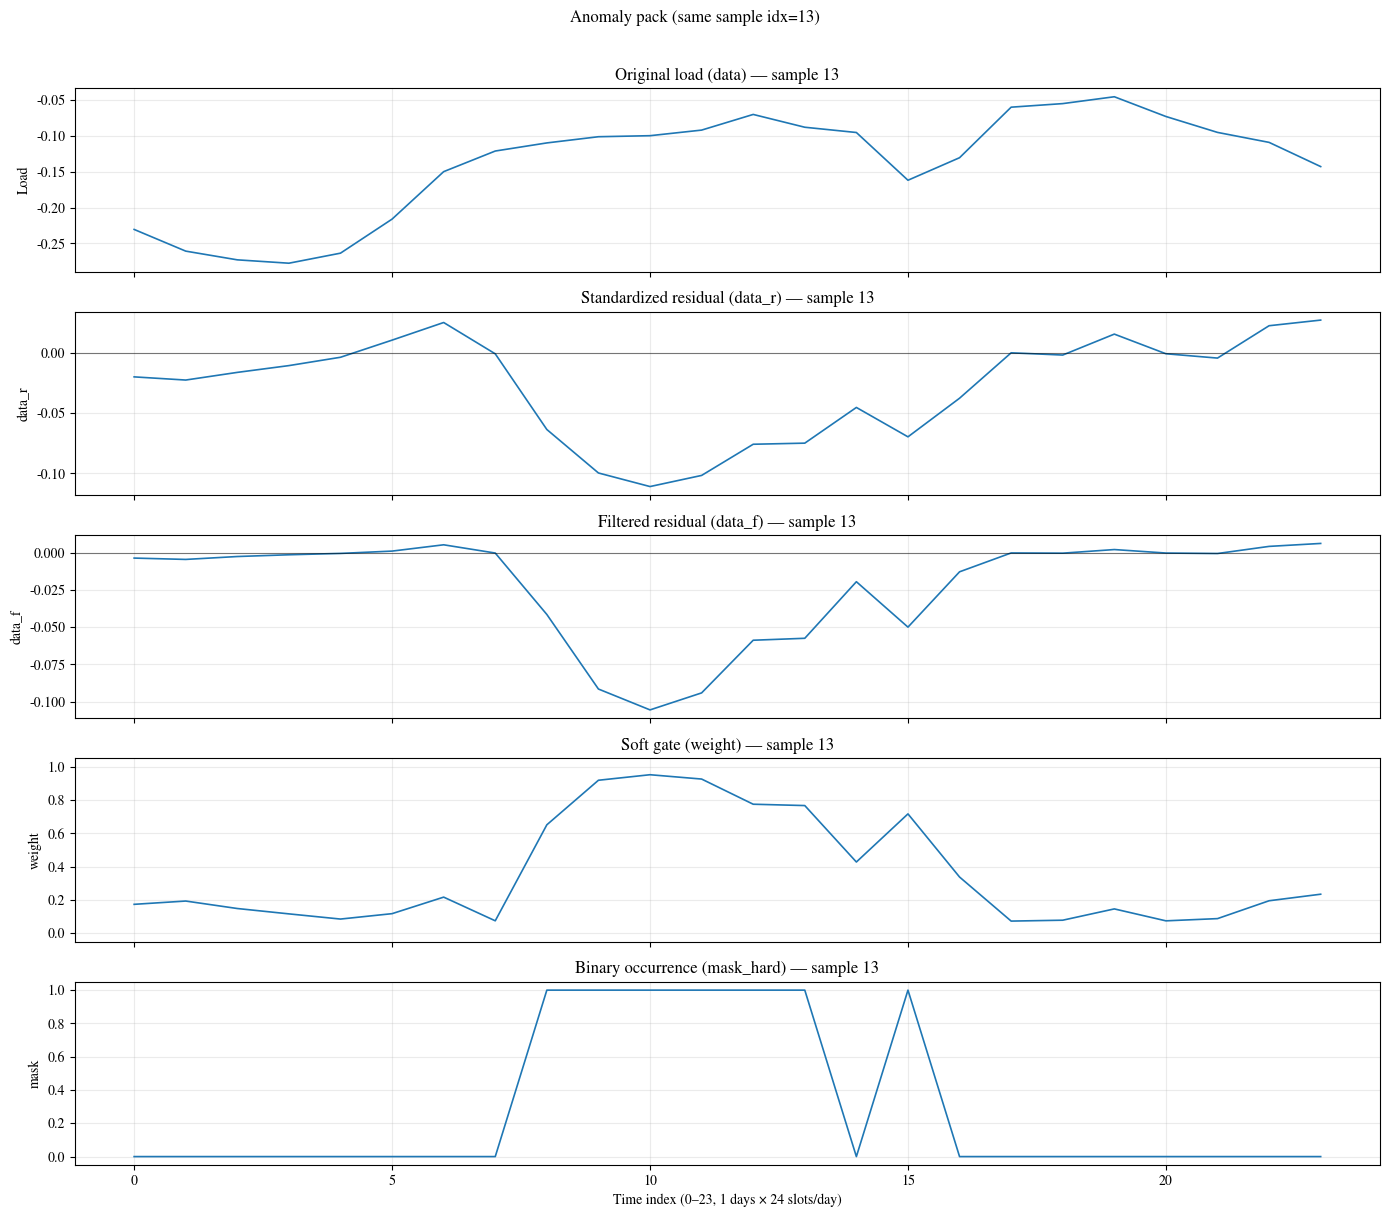

sampled_idx=13


In [10]:
fig, axes, sampled_idx = plot_anomaly_pack_sample(
    data,           # 归一化负荷
    data_r,
    data_f,
    weight,
    mask_hard,
    random_state=np.random.randint(0, 1000000),
    num_days=1,         # 每条样本 = 1 天
    slots_per_day=24,   # 每天 24 小时
)
print(f"sampled_idx={sampled_idx}")

In [11]:
print(M.shape)
print(cond.shape)
# SynEnergy expects cond in [0, K) (0-indexed); notebook uses 1..4 for zone IDs
cond_synenergy = (cond - 1).astype(np.float32)
np.save('../SynEnergy/Data/Power/CA_seq_24_sample_1460.npy', M)
np.save('../SynEnergy/Data/Power/CA_seq_24_sample_1460_condition.npy', cond_synenergy)

(1460, 24, 1)
(1460, 1, 1)
